# Choosing settings: regularisation and tuning

*Session 7, block 2 · Course material, CC BY 4.0. Sections marked "Adapted from" reuse third-party material under its licence (see [Further reading](#Further-reading)).*

After this block you can tell parameters from hyperparameters, control the complexity of a linear model with ridge and lasso regularisation, diagnose underfitting and overfitting with validation and learning curves, tune hyperparameters with `GridSearchCV` and `RandomizedSearchCV` without leaking, estimate the tuned procedure with nested cross-validation, and close a project with one final test on held-out data.

The running question continues from block 1: **what error should a host who lists a first flat in Berlin expect from a tuned price model?** The practice: tune the ridge and lasso penalties of the price model, read its validation and learning curves, estimate the tuned model's error with nested cross-validation, and only then run the final test on held-out hosts.

## Teaching map

The **core path** (45 minutes) is marked with a ✔. Sections labelled *(depth: self-study or if time allows)* go further and can be skipped in class.

| # | Section | Core min | What it delivers |
|---|---|---|---|
| 0 | The case: 480 columns and locked test hosts | 3 ✔ | the price table with amenities; 20 % of the hosts locked away before anything else |
| 1 | Parameters and hyperparameters | 4 ✔ | what `fit` learns and what we choose |
| 2 | Regularisation with ridge and lasso | 9 ✔ | the penalty, shrinkage, sparsity, why scaling matters |
| 3 | Validation curves and learning curves | 9 ✔ | under- and overfitting, more data or more penalty |
| 4 | Hyperparameter tuning with GridSearchCV and RandomizedSearchCV | 9 ✔ | systematic, reproducible search; tuning ridge *and* lasso |
| 5 | Nested cross-validation | 5 ✔ | an honest estimate of the tuning procedure |
| 6 | The final test on held-out data | 3 ✔ | one look at the locked hosts |
| 7 | Worked example: the error for a first-time host | 3 ✔ | the reported number, with a cluster-bootstrap interval |
| | Check your understanding, exercises, debrief | 45 | |

```mermaid
flowchart LR
    H["Choose candidate<br/>hyperparameters"] --> CV["Cross-validate<br/>each candidate<br/>(host-grouped folds)"]
    CV --> D{"Training vs<br/>validation score"}
    D -->|"both low"| U["Underfitting:<br/>less penalty, more features"]
    D -->|"large gap"| O["Overfitting:<br/>more penalty, more data"]
    D -->|"high, close"| B["Keep best setting,<br/>refit on all dev data"]
    U --> H
    O --> H
    B --> N["Nested CV, then<br/>final test once"]
```

The code cells build on each other; run them in order. The first cell moves to the repository root, where the case-study paths start (`uv run python case-study/prepare_airbnb.py` creates the data). The whole notebook runs in a few minutes; the slowest cells are marked.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## 0 · The case: 480 columns and locked test hosts

The table is the short-stay table of block 1 (6,675 listings priced between €10 and €1,000, log price as target). This time the model also gets the **amenities** that hosts tick on the listing page (dishwasher, elevator, balcony, ...): one 0/1 column for each amenity that at least 20 listings mention. Next we load the data. `json.loads` turns the amenity text into a Python list; `MultiLabelBinarizer` turns lists into 0/1 columns.

In [2]:
import json

import numpy as np
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

lst = pd.read_parquet("case-study/data/airbnb/listings.parquet")
bnb = lst[(lst["minimum_nights"] < 28) & lst["price"].between(10, 1000)].reset_index(drop=True)
bnb["dist_km"] = np.hypot((bnb["latitude"] - 52.5219) * 111.2, (bnb["longitude"] - 13.4132) * 68.0)
mlb = MultiLabelBinarizer()
amen = pd.DataFrame(mlb.fit_transform(bnb["amenities"].map(json.loads)), columns=["am_" + a for a in mlb.classes_])
amen = amen.loc[:, amen.sum() >= 20]                          # amenities listed by at least 20 listings
print(len(bnb), "listings,", amen.shape[1], "amenity columns")

6675 listings, 257 amenity columns


> **Note.** The list of amenities (those with at least 20 listings) is chosen on all rows before splitting. It does not look at prices, so this shortcut leaks almost nothing; Session 9 shows how to learn such a list inside the pipeline.

Next we assemble the feature table and the preprocessing. Numbers get a median imputer (with an indicator column for "was missing") and a scaler, categories a one-hot encoder, amenities a scaler. `make_column_transformer` applies each step to its columns; together they produce about 480 model columns.

In [3]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "minimum_nights",
       "availability_365", "number_of_reviews", "review_scores_rating"]
cat = ["room_type", "district", "neighbourhood", "property_type"]
X_all = pd.concat([bnb[num + cat], amen], axis=1)
y_all, price_all, hosts_all = np.log(bnb["price"]), bnb["price"], bnb["host_id"]
prep = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), num),
    (OneHotEncoder(handle_unknown="ignore"), cat),
    (StandardScaler(), list(amen.columns)))

**Lock the test hosts away first.** Every choice in this block (penalty, model, settings) will be made on the development data. So before we look at anything, we lock away 20 % of the hosts with all their listings, exactly as in block 1, and do not touch them until section 6. `GroupShuffleSplit` keeps each host on one side; from now on `X`, `y` and `hosts` are the development part only, and all cross-validation uses host-grouped folds (`GroupKFold`), because the question is about new hosts.

In [4]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

dev, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0).split(X_all, y_all, groups=hosts_all))
X, y, hosts = X_all.iloc[dev], y_all.iloc[dev], hosts_all.iloc[dev]          # development data
X_test, y_test = X_all.iloc[test], y_all.iloc[test]                         # locked until section 6
cv = GroupKFold(5)                                                          # whole hosts per fold
print(len(dev), "development listings,", len(test), "test listings of", hosts_all.iloc[test].nunique(), "hosts;",
      prep.fit_transform(X).shape[1], "model columns")

5421 development listings, 1254 test listings of 748 hosts; 476 model columns


## 1 · Parameters and hyperparameters

**Concept.** **Parameters** are learned from the data during `fit`: the coefficients and intercept of a linear or logistic regression, the split points of a tree, the medians stored by an imputer. **Hyperparameters** are set *before* training and control how learning happens: the penalty strength `alpha` of ridge regression, `C` of logistic regression, the number of neighbours `n_neighbors` of k-NN, the depth of a tree, the learning rate of gradient boosting.

An analogy: a recipe's oven temperature and baking time are hyperparameters, chosen by the cook; how the dough rises is the learning. Different settings give different cakes, and you judge them by tasting new slices, not by the cook's opinion.

Hyperparameters are chosen by comparing **validation** scores, never training scores, because the training score almost always prefers the most flexible setting. Example: for k-NN with *k* = 1 the training error is zero, because each training row is its own nearest neighbour. Choosing *k* by training error would always give *k* = 1, the most overfitted model.

**Why it matters.** The same algorithm can underfit or overfit depending on its hyperparameters. Treating them as part of the model to be validated, and choosing them by a reproducible procedure, separates a sound workflow from tuning by hand until the test score looks good.

Next we look at both kinds in the ridge pipeline. Every scikit-learn estimator lists its hyperparameters with `get_params()`; inside a pipeline they are named `step__name` (two underscores). Learned parameters appear after `fit` and end with an underscore, such as `coef_`.

**Predict before running:** how many coefficients will the ridge model learn?

In [5]:
from sklearn.linear_model import Ridge

model = make_pipeline(prep, Ridge())
print("alpha (hyperparameter, chosen by us):", model.get_params()["ridge__alpha"])
model.fit(X, y)
print("coefficients (parameters, learned):  ", model[-1].coef_.shape)
print("first learned median of the imputer: ", model[0].transformers_[0][1][0].statistics_[0])

alpha (hyperparameter, chosen by us): 1.0


coefficients (parameters, learned):   (476,)
first learned median of the imputer:  3.0


**In practice.**
- Gradient boosting models (Session 10) have a dozen hyperparameters (learning rate, depth, number of trees); industry teams tune them systematically and log every trial, for example with MLflow (Session 16).
- AutoML systems such as auto-sklearn (Feurer et al., 2015) treat the choice of algorithm itself as one more hyperparameter and search over it with cross-validation.

> **Note.** "Default settings" are also a choice. Report which hyperparameters you used, including defaults, so that results can be reproduced.

## 2 · Regularisation with ridge and lasso

**Concept.** Ordinary least squares (OLS) chooses the coefficients *b* that minimise the sum of squared residuals. With many features, correlated features or few rows, the coefficients become large and unstable, and the model overfits. **Regularisation** adds a penalty for large coefficients to what the model minimises:

- **Ridge** regression minimises Σ(yᵢ − ŷᵢ)² + α Σ bⱼ². The penalty is the sum of *squared* coefficients. It shrinks all coefficients towards zero but rarely makes any of them exactly zero (Hoerl & Kennard, 1970).
- **Lasso** regression minimises (1/2n) Σ(yᵢ − ŷᵢ)² + α Σ |bⱼ|. The penalty is the sum of *absolute* coefficients. It sets some coefficients exactly to zero, so the lasso also **selects features** (Tibshirani, 1996).
- **Elastic net** mixes both penalties (`ElasticNet(alpha, l1_ratio)`).
- The penalty strength **α** (`alpha`) is a hyperparameter. α = 0 gives OLS; a very large α forces all coefficients towards zero, and the model predicts the mean. In between lies a trade-off: more penalty means less variance but more bias.
- Logistic regression in scikit-learn is regularised by default. Its hyperparameter is **C = 1/α**: a *small* C means a *strong* penalty.

Worked example with one feature: suppose least squares gives *b* = 4 on a standardised feature. With a ridge penalty that shrinks by the factor 1/(1 + α/Σx²) = 0.8, the ridge coefficient is 3.2: pulled towards zero, but not zero. A lasso penalty subtracts a fixed amount instead (soft thresholding): with a threshold of 1 the coefficient becomes 3, and a coefficient smaller than the threshold, say 0.6, becomes exactly 0.

> **Note.** The penalty treats all coefficients alike, so the features must be on the same scale. Always put a scaler before `Ridge`, `Lasso` or `LogisticRegression` in a pipeline. The depth section below shows what happens otherwise.

**Why it matters.** Regularisation is the main tool to control the complexity of a linear model without removing features by hand. It stabilises coefficients when features are correlated (`accommodates`, `bedrooms` and `beds`; amenities that come together, such as oven, stove and baking sheet), it lets you use many features (amenity indicators, one-hot columns for 138 neighbourhoods, word counts in Session 13), and the lasso gives shorter, easier-to-read models.

Next we compare OLS, ridge and two lassos with host-grouped cross-validation. `cross_validate(..., return_train_score=True)` gives training and validation R²; after a fit on all development rows we report the largest coefficient and the number of non-zero ones.

In [6]:
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import cross_validate

for name, reg in [("OLS", LinearRegression()), ("ridge a=10", Ridge(alpha=10)),
                  ("lasso a=0.001", Lasso(alpha=0.001, max_iter=5000)), ("lasso a=0.01", Lasso(alpha=0.01, max_iter=5000))]:
    m = make_pipeline(prep, reg)
    res = cross_validate(m, X, y, cv=cv, groups=hosts, scoring="r2", return_train_score=True)
    coef = m.fit(X, y)[-1].coef_
    print(f"{name:13s} train {res['train_score'].mean():.3f}  valid {res['test_score'].mean():.3f}  "
          f"largest |b| {np.abs(coef).max():.2f}  non-zero {(coef != 0).sum()}")

OLS           train 0.720  valid 0.585  largest |b| 0.94  non-zero 476


ridge a=10    train 0.709  valid 0.605  largest |b| 0.55  non-zero 476


lasso a=0.001 train 0.689  valid 0.609  largest |b| 0.74  non-zero 271


lasso a=0.01  train 0.615  valid 0.572  largest |b| 0.29  non-zero 84


OLS gives some columns large coefficients (up to 0.94 on the log scale): rare neighbourhood and property-type dummies with a handful of listings, which the model fits almost exactly. Ridge with α = 10 shrinks the largest coefficient to 0.55 and gains a little validation R². The lasso with α = 0.001 keeps 271 of 476 columns at the same validation score; with α = 0.01 it keeps 84 and loses some R²: too much penalty starts to underfit.

Next we look at which amenities the stronger lasso keeps. `get_feature_names_out()` returns the names of the model columns; `.filter(like="__am_")` keeps the amenity columns.

In [7]:
lasso = make_pipeline(prep, Lasso(alpha=0.01, max_iter=5000)).fit(X, y)
b = pd.Series(lasso[-1].coef_, index=lasso[0].get_feature_names_out())
b_amen = b.filter(like="__am_")
print((b_amen != 0).sum(), "amenities kept; largest positive coefficients:")
print(b_amen.sort_values().tail(5).rename(lambda s: s.split("__am_")[1]).round(3).to_string())

70 amenities kept; largest positive coefficients:
Smart lock    0.018
Crib          0.021
Safe          0.026
Elevator      0.032
Dishwasher    0.038


Each coefficient is small: one standard deviation more of an amenity indicator changes the predicted price by a few percent (`np.exp(b) - 1`). Most one-hot columns drop out of the strong lasso because the pipeline does not scale them: a rare 0/1 column has a small spread, so the same penalty weighs more heavily on it. On data of this size the penalty buys stability and a shorter model rather than accuracy; section 3 shows when it buys accuracy as well.

**In practice.**
- Genetics: lasso-type models are used to build polygenic risk scores from hundreds of thousands of genetic variants, where most effects are expected to be zero.
- Credit scoring: regularised logistic regression is a standard way to keep scorecard coefficients stable when many correlated customer attributes are available.
- Text classification (Session 13): logistic regression with an L2 penalty on tens of thousands of word features is a strong baseline.

> **Note.** Coefficients of a regularised model are biased towards zero. Do not read them as unbiased effect sizes with standard errors ("a dishwasher raises the price by x %"); for inference, use the unpenalised models and tests of Sessions 5 and 6.

> **Note.** Choosing α by its test score is the same mistake as choosing a model by its test score. Choose α by cross-validation on the development data.

### Coefficient paths: watching the penalty work *(depth: self-study or if time allows)*

*Adapted from ISLP Lab 6 "Linear Models and Regularization Methods" ([ISLP labs](https://github.com/intro-stat-learning/ISLP_labs), BSD-2-Clause).*

A **regularisation path** shows every coefficient as a function of the penalty. To keep the picture readable we use only the nine numeric columns. Next we standardise them (after median imputation) and fit ridge and lasso for 30 values of α between 10⁻³ and 10⁴. `np.logspace(a, b, n)` gives *n* values evenly spaced on the log scale, the natural scale for a penalty.

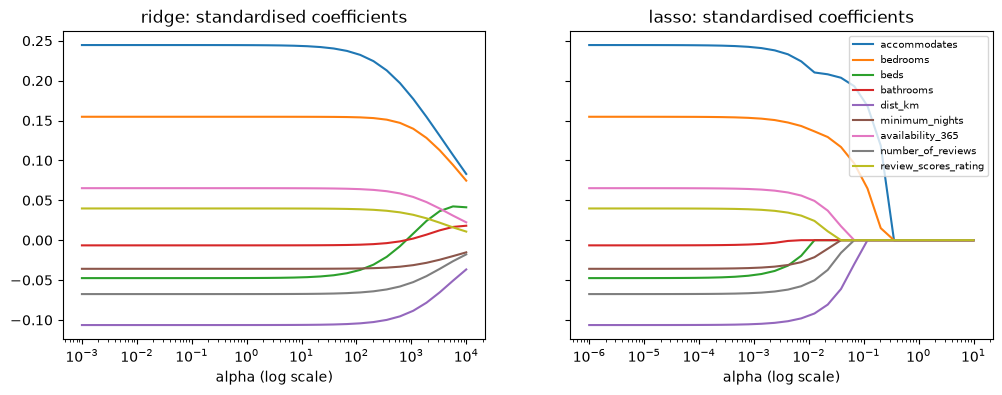

In [8]:
import matplotlib.pyplot as plt

Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X[num]))
alphas = np.logspace(-3, 4, 30)
paths = {"ridge": [Ridge(alpha=a).fit(Z, y).coef_ for a in alphas],
         "lasso": [Lasso(alpha=a / 1000, max_iter=10_000).fit(Z, y).coef_ for a in alphas]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, coefs) in zip(axes, paths.items()):
    ax.semilogx(alphas if name == "ridge" else alphas / 1000, coefs)
    ax.set(xlabel="alpha (log scale)", title=f"{name}: standardised coefficients")
axes[1].legend(num, fontsize=7, loc="upper right")
plt.show()

Read the plot from left to right. With little penalty both models give the OLS coefficients. As α grows, ridge pulls all nine coefficients smoothly towards zero, none of them reaching it. The lasso drops coefficients one after another to exactly zero: the last survivors (typically `accommodates` and the distance to the centre) are the features that carry most of the signal. (The lasso's α is on another scale, because scikit-learn divides its squared error by 2*n*.)

### Why scaling matters for the penalty *(depth: self-study or if time allows)*

*Adapted from "Regularization of linear regression model" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

Coefficients describe the effect of one unit of a feature. A feature measured in small units (kilometres) needs a large coefficient for the same effect as a feature in large units (number of reviews, up to several hundred). The penalty does not know about units: it punishes large coefficients, so without scaling it punishes the small-unit feature more, although nothing says it is less important. Scaling makes the penalty neutral. Many numerical solvers also work better when features are on similar scales.

Next we square the numeric features and their pairwise products with `PolynomialFeatures(degree=2)`, which makes 54 columns of very different magnitudes, and compare ridge with and without a scaler. `cross_validate(..., return_estimator=True)` keeps the fitted models so that we can inspect their coefficients fold by fold.

In [9]:
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures

impute = SimpleImputer(strategy="median")
variants = {"OLS, unscaled": make_pipeline(impute, PolynomialFeatures(2, include_bias=False), LinearRegression()),
            "ridge a=10, unscaled": make_pipeline(impute, PolynomialFeatures(2, include_bias=False), Ridge(alpha=10)),
            "ridge a=10, scaled": make_pipeline(impute, MinMaxScaler(), PolynomialFeatures(2, include_bias=False),
                                                Ridge(alpha=10))}
poly_res = {}
for name, m in variants.items():
    poly_res[name] = cross_validate(m, X[num], y, cv=cv, groups=hosts, scoring="r2",
                                    return_train_score=True, return_estimator=True)
    print(f"{name:21s} train R2 {poly_res[name]['train_score'].mean():.3f}  valid R2 {poly_res[name]['test_score'].mean():.3f}")

OLS, unscaled         train R2 0.510  valid R2 0.135
ridge a=10, unscaled  train R2 0.513  valid R2 0.115
ridge a=10, scaled    train R2 0.454  valid R2 0.434


Next we put the 54 coefficients of the five fold models into a DataFrame (one row per fold) and summarise how stable they are: the largest coefficient in absolute value, and the median over the 54 columns of the fold-to-fold standard deviation divided by the absolute mean (a coefficient of variation; large values mean that a coefficient changes a lot, or even flips sign, between folds).

In [10]:
names = variants["OLS, unscaled"][:2].fit(X[num]).get_feature_names_out(num)
rows = {}
for name, res in poly_res.items():
    w = pd.DataFrame([est[-1].coef_ for est in res["estimator"]], columns=names)
    rows[name] = {"largest |b|": w.abs().max().max(),
                  "median relative spread across folds": (w.std() / w.mean().abs()).median()}
pd.DataFrame(rows).T.round(3)

,largest |b|,median relative spread across folds
"OLS, unscaled",0.155,0.536
"ridge a=10, unscaled",0.277,0.486
"ridge a=10, scaled",0.993,0.336


Without scaling, the polynomial model overfits badly (validation R² 0.135 against 0.510 in training), and a ridge penalty of the same strength does not help (0.115), because it hits columns of very different scales very unequally. After `MinMaxScaler` (each feature mapped to the range 0 to 1, which stays 0 to 1 after squaring) the same penalty lifts the validation R² to 0.434, and the coefficients are more stable across folds (median relative spread 0.34 against 0.54). The largest coefficient grows only because each scaled column now spans 0 to 1 instead of its natural unit: coefficients of differently scaled models are not comparable.

> **Note.** One-hot columns are often left unscaled, since they are already 0 or 1. Scaling them gives rare categories the same weight in the penalty as common ones, which can help or hurt; the INRIA notebook discusses the trade-off.

### `RidgeCV`: a penalty search built into the model *(depth: self-study or if time allows)*

*Adapted from "Regularization of linear regression model" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

Some estimators search their own penalty efficiently: `RidgeCV`, `LassoCV`, `ElasticNetCV`, `LogisticRegressionCV`. `RidgeCV(alphas=...)` uses a fast leave-one-out formula. Wrapped in an outer `cross_validate`, it gives a nested cross-validation for free (section 5): the inner search picks α on each training part, the outer folds score the tuned model. Next we run it with 50 candidate penalties and look at the α chosen in each outer fold.

In [11]:
from sklearn.linear_model import RidgeCV

ridge_cv = make_pipeline(prep, RidgeCV(alphas=np.logspace(-2, 4, 50)))
res = cross_validate(ridge_cv, X, y, cv=cv, groups=hosts, scoring="r2", return_estimator=True)
print("validation R2 per outer fold:", res["test_score"].round(3))
print("alpha chosen in each fold:   ", [round(float(est[-1].alpha_), 1) for est in res["estimator"]])

validation R2 per outer fold: [0.628 0.598 0.589 0.618 0.584]
alpha chosen in each fold:    [6.6, 6.6, 4.9, 6.6, 4.9]


The chosen penalty varies between folds, but within a narrow range, and the scores are stable. If the chosen α jumped across orders of magnitude between folds, that would point to a problem with the data (outliers, a few dominant rows) or with the preprocessing.

> 📖 **Read more:** [extras/10-ridge-regularisation.ipynb](extras/10-ridge-regularisation.ipynb) (INRIA scikit-learn MOOC): the same three steps on the Ames housing data, with the cross-validated error curve of `RidgeCV`.
>
> 📖 **Read more:** [extras/11-islp-ridge-lasso-lab.ipynb](extras/11-islp-ridge-lasso-lab.ipynb) (ISLP labs): subset selection, ridge, lasso, PCR and PLS on the `Hitters` data, with cross-validated penalties. A few upstream cells fail with NumPy 2 and current scikit-learn.

## 3 · Validation curves and learning curves

**Concept.** Two plots diagnose underfitting and overfitting.

- A **validation curve** shows the training score and the cross-validated validation score as a function of **one hyperparameter**. Where both are poor, the model **underfits** (too simple, high bias). Where the training score is good and the validation score much worse, it **overfits** (too flexible, high variance). The best setting is where the validation score peaks.
- A **learning curve** shows the same two scores as a function of the **number of training rows**. If the curves meet at a poor level, more data will not help: the model is too simple. If a large gap remains and the validation curve is still improving, more data (or a simpler model) will help.

**Why it matters.** The two curves tell you *what to do next*. A gap means: regularise more, simplify or collect more data. Two poor curves mean: add features or use a more flexible model. Without them, people try random changes. The curves also make the bias–variance trade-off of Session 6 visible on real data.

*The plotting tools and the reading of the curves are adapted from "Overfit-generalization-underfit" and "Effect of the sample size in cross-validation" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

**Predict before running:** with all development listings (about 5,400 rows for 480 columns), will the ridge penalty matter much? And with only 1,000 listings?

Next we draw the validation curve of the ridge penalty twice: on all development listings and on a random 1,000 of them. `ValidationCurveDisplay.from_estimator(model, X, y, param_name=..., param_range=..., cv=...)` cross-validates every value and plots both curves with their spread; `groups=` passes the hosts to the grouped folds.

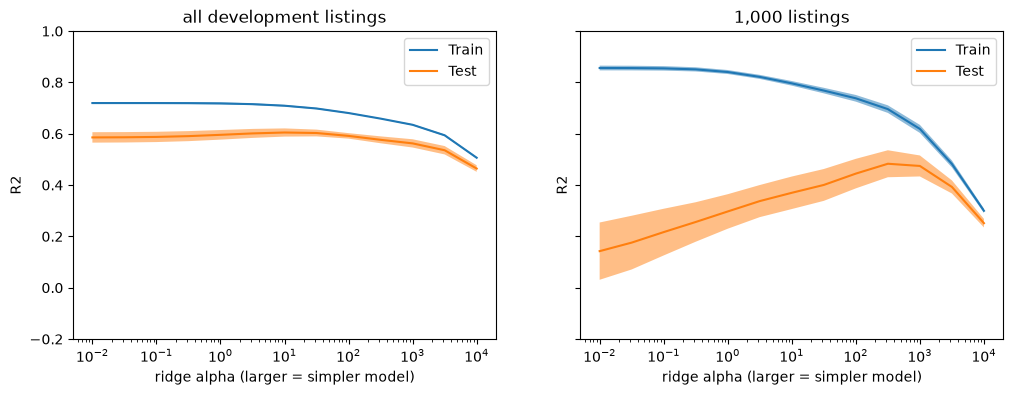

In [12]:
import matplotlib.pyplot as plt
from sklearn.model_selection import ValidationCurveDisplay

alphas = np.logspace(-2, 4, 13)
small = np.random.default_rng(0).choice(len(X), 1000, replace=False)     # a city with 1,000 listings
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (label, rows) in zip(axes, [("all development listings", np.arange(len(X))), ("1,000 listings", small)]):
    ValidationCurveDisplay.from_estimator(make_pipeline(prep, Ridge()), X.iloc[rows], y.iloc[rows],
                                          groups=hosts.iloc[rows], param_name="ridge__alpha", param_range=alphas,
                                          cv=cv, scoring="r2", std_display_style="fill_between", ax=ax)
    ax.set(xscale="log", ylim=(-0.2, 1), title=label, xlabel="ridge alpha (larger = simpler model)")
plt.show()

With all development listings the penalty hardly matters until it becomes very large: 480 columns are few for about 5,400 rows. With 1,000 listings the picture has three regions, as in the textbook:

- **small α (left):** training R² high, validation R² far lower: the model memorises the training listings (overfitting);
- **large α (right):** both scores fall: the model is too constrained (underfitting);
- **in between:** the validation score peaks. That is the setting to choose, and it lies at a much larger α than with all listings.

The fewer rows per column, the more the penalty matters. Look at the shaded spread as well as the means: where the bands overlap, the differences between settings are not reliable.

Next we draw learning curves for ridge (α = 10) and for gradient boosting (Session 10; here a black box). Trees need no scaling and no one-hot columns: an `OrdinalEncoder` that numbers the categories is enough and keeps the table small, so the boosting pipeline gets its own preprocessing `tree_prep` (the INRIA grid-search notebook makes the same choice). `LearningCurveDisplay.from_estimator(..., train_sizes=...)` refits the model on growing fractions of each training part. *(One of the slower cells: up to a minute.)*

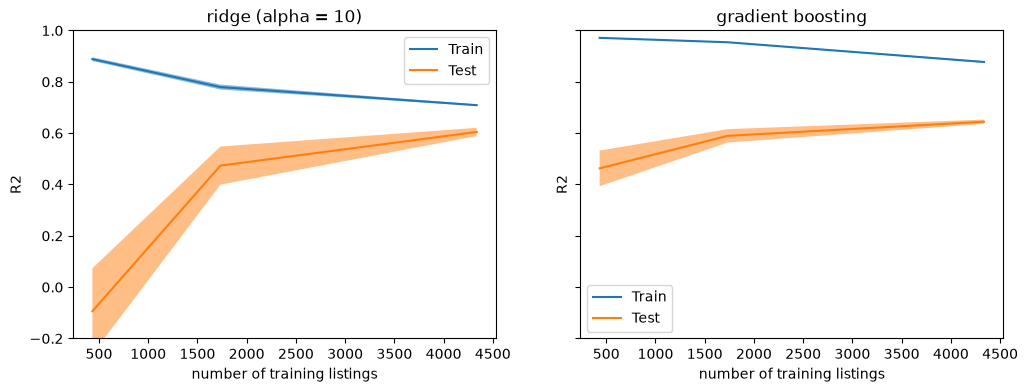

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import LearningCurveDisplay
from sklearn.preprocessing import OrdinalEncoder

tree_prep = make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                    encoded_missing_value=-1), cat), remainder="passthrough")
gbm = make_pipeline(tree_prep, HistGradientBoostingRegressor(random_state=0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (label, est) in zip(axes, [("ridge (alpha = 10)", make_pipeline(prep, Ridge(alpha=10))),
                                   ("gradient boosting", gbm)]):
    LearningCurveDisplay.from_estimator(est, X, y, groups=hosts, cv=cv, train_sizes=[0.1, 0.4, 1.0],
                                        scoring="r2", score_type="both", std_display_style="fill_between", ax=ax)
    ax.set(title=label, ylim=(-0.2, 1), xlabel="number of training listings")
plt.show()

For ridge the gap closes as listings are added and both curves level off: more listings of the same kind will help little; better features might. For gradient boosting the training score stays far above the validation score and the validation score is still rising at the right edge: this model would profit from more data, and it already beats ridge at the larger sizes. If a validation curve levels off despite more data, the remaining error is either a model that is too simple, or noise the features cannot explain.

### What is noise? *(depth: self-study or if time allows)*

*Adapted from "Overfit-generalization-underfit" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

"Overfitting means learning the noise", but what is noise here? It can be measurement error (a typo in a price) or label noise. In practice the most common source is **a relevant feature that was not measured**. A host who wants to fill a gap in the calendar lowers the price for a week; a flat has a view of the Spree that no column describes. The model cannot see these causes, so from its point of view the price varies at random. Two flats with identical features can have different prices. The way to make a model robust to such noise is the same as for overfitting: keep the model simple enough (tune its hyperparameters) and collect more labelled rows.

**In practice.**
- Banko and Brill (2001) plotted learning curves for a word-disambiguation task up to one billion words and showed that simple learners kept improving with more data, which influenced the move towards large training corpora in language technology.
- Teams deciding whether to pay for more labelled data (for example annotation of medical images) use learning curves to estimate the benefit before buying.

> **Note.** A learning curve is expensive: `learning_curve` fits the model `len(train_sizes) × k` times. Start with a sample and three to five sizes.

> **Note.** Use a log scale for penalties such as α and C. The interesting range usually spans several orders of magnitude (0.001 to 1,000), not 1 to 10.

> 📖 **Read more:** [extras/12-validation-curve.ipynb](extras/12-validation-curve.ipynb) and [extras/13-learning-curve.ipynb](extras/13-learning-curve.ipynb) (INRIA scikit-learn MOOC): the validation curve of a decision tree's depth and its learning curve on the California housing data.
>
> 📖 **Read more:** [extras/14-learning-curve-sklearn.ipynb](extras/14-learning-curve-sklearn.ipynb) (scikit-learn gallery): learning curves for naive Bayes and an SVM, and how fit and prediction times grow with the training size.
>
> 📖 **Read more:** [extras/01-model-validation.ipynb](extras/01-model-validation.ipynb) (Python Data Science Handbook, ch. 5.3): validation curves for the degree of a polynomial model and learning curves for two data-set sizes, with the bias–variance picture behind them.

## 4 · Hyperparameter tuning with GridSearchCV and RandomizedSearchCV

**Concept.** Tuning is the systematic search for good hyperparameters by cross-validation.

- **`GridSearchCV`** tries every combination in a grid and cross-validates each. The number of combinations is the product of the number of values per hyperparameter, so it grows fast: six values of `alpha` × 5 folds = 30 fits; four learning rates × three tree sizes × 5 folds = 60.
- **`RandomizedSearchCV`** draws `n_iter` combinations from distributions, for example `scipy.stats.loguniform(0.01, 0.3)` for a learning rate, which spreads the draws evenly over orders of magnitude. Its cost is fixed by `n_iter`, whatever the number of hyperparameters.
- Both **refit** the best setting on all data passed to `fit` (`best_estimator_`), report `best_params_` and `best_score_`, and store every trial in `cv_results_`. A fitted search can be used like a model: `predict` uses the refitted best model.
- Wrapping preprocessing and model in a `Pipeline` lets the search tune both, without leaking (block 1). Hyperparameters of a step are addressed as `step__name`, for example `ridge__alpha`. When the splitter needs groups, pass them to `fit`: `search.fit(X, y, groups=hosts)`.

*The following subsections are adapted from "Hyperparameter tuning by grid-search" and "Hyperparameter tuning by randomized-search" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

![Tuning inside a train-test split: the training part is split again by k-fold cross-validation into training and validation folds to choose the hyperparameters; the best setting is refitted on the whole training part and evaluated once on the test part.](../figures/cross_validation_train_test_diagram.png)

*Figure: INRIA scikit-learn MOOC, CC BY 4.0. The green folds are the validation sets, the blue part is our locked test hosts.*

### A grid for one penalty

Next we search the ridge penalty over six values with host-grouped folds. `pd.DataFrame(grid.cv_results_)` turns the stored trials into a table.

In [14]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(make_pipeline(prep, Ridge()), {"ridge__alpha": [0.1, 1, 3, 10, 30, 100]}, cv=cv, scoring="r2")
grid.fit(X, y, groups=hosts)
print(grid.best_params_, round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_)[["param_ridge__alpha", "mean_test_score", "std_test_score", "rank_test_score"]].round(3)

{'ridge__alpha': 10} 0.605


,param_ridge__alpha,mean_test_score,std_test_score,rank_test_score
0,0.1,0.587,0.020,6
1,1.0,0.596,0.019,4
2,3.0,0.601,0.018,3
3,10.0,0.605,0.016,1
4,30.0,0.603,0.013,2
5,100.0,0.592,0.011,5


The optimum is flat: several values of α score within a fraction of the fold-to-fold standard deviation of the best. For this model α hardly matters as long as it is not very large, which is a finding worth reporting.

> **Note.** If the best value lies at the edge of the grid (for example `alpha=100` when the grid ends at 100), the optimum may be outside. Extend the range before you conclude.

### A grid for two hyperparameters

Gradient boosting has two closely linked knobs: the `learning_rate` (how strongly each new tree corrects the errors of the previous ones) and `max_leaf_nodes` (how large each tree may grow; Session 10 explains both). Next we cross a few values of each and draw the mean validation score as a heatmap. `pivot_table` reshapes the trials into a learning rate × leaves table; `seaborn.heatmap` colours it. To keep the cost down we use three folds. *(Up to a minute.)*

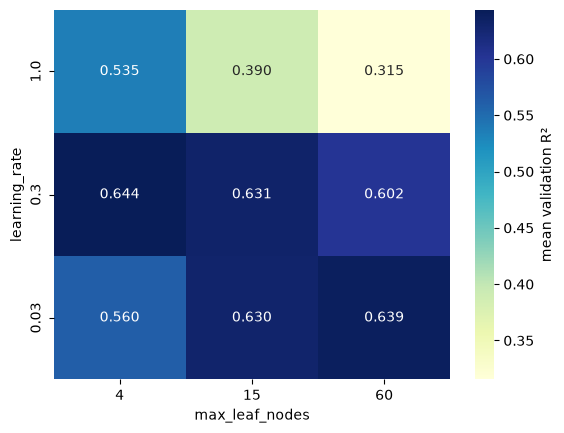

In [15]:
import seaborn as sns

grid2 = GridSearchCV(gbm, {"histgradientboostingregressor__learning_rate": [0.03, 0.3, 1],
                           "histgradientboostingregressor__max_leaf_nodes": [4, 15, 60]}, cv=GroupKFold(3), scoring="r2")
grid2.fit(X, y, groups=hosts)
res2 = pd.DataFrame(grid2.cv_results_).rename(columns=lambda c: c.split("__")[-1])
heat = res2.pivot_table(values="mean_test_score", index="learning_rate", columns="max_leaf_nodes")
ax = sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "mean validation R²"})
ax.invert_yaxis()
plt.show()

Three lessons carry over from the INRIA example to our data. A learning rate that is too high (a learning rate of 1) degrades the model, and no tree size can repair it. Outside that region, the best tree size depends on the learning rate: larger trees go with smaller steps, so the good settings lie on a "diagonal". And **there is no unique optimum**: four cells score within 0.015 of the best (0.644), which is less than the fold-to-fold spread of these scores. The heatmap shows only means; check `std_test_score` before calling one setting better than another.

### Randomised search

A grid has two weaknesses. Its cost multiplies with every hyperparameter, and its regular lines can miss a good region that lies between them. When only a few hyperparameters really matter (the usual case, Bergstra & Bengio, 2012), a random search spends its budget better: each draw tries a *new* value of every hyperparameter, while a grid tries the same few values of the important one again and again.

![Grid search and random search with nine trials each, over one important and one unimportant hyperparameter: the grid tests only three distinct values of the important one, the random search nine.](../figures/grid_vs_random_search.svg)

*Figure: INRIA scikit-learn MOOC, CC BY 4.0.*

`RandomizedSearchCV` takes distributions instead of lists. `scipy.stats.loguniform(a, b)` draws floats evenly on the log scale (0.1 is as far from 1 as 10 is). For integers on a log scale the INRIA notebook uses a small wrapper class with an `rvs` method, which is all scikit-learn needs. Next we define it.

In [16]:
from scipy.stats import loguniform


class loguniform_int:
    # Integer-valued version of the log-uniform distribution (INRIA scikit-learn MOOC).
    def __init__(self, a, b):
        self._distribution = loguniform(a, b)

    def rvs(self, *args, **kwargs):
        return self._distribution.rvs(*args, **kwargs).astype(int)

Next we search five hyperparameters of gradient boosting with 8 random draws and three folds: the two above, the strength of its own L2 penalty, the minimum number of listings per leaf, and the number of histogram bins. `random_state=0` fixes the draws. *(Up to a minute.)*

In [17]:
from sklearn.model_selection import RandomizedSearchCV

space = {"histgradientboostingregressor__l2_regularization": loguniform(1e-6, 1e3),
         "histgradientboostingregressor__learning_rate": loguniform(0.01, 1),
         "histgradientboostingregressor__max_leaf_nodes": loguniform_int(2, 64),
         "histgradientboostingregressor__min_samples_leaf": loguniform_int(1, 100),
         "histgradientboostingregressor__max_bins": loguniform_int(2, 255)}
rand = RandomizedSearchCV(gbm, space, n_iter=8, cv=GroupKFold(3), scoring="r2", random_state=0)
rand.fit(X, y, groups=hosts)
cols = ["param_" + k for k in space] + ["mean_test_score", "std_test_score"]
pd.DataFrame(rand.cv_results_)[cols].rename(columns=lambda c: c.split("__")[-1]).sort_values("mean_test_score", ascending=False).round(3).head(6)

,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,max_bins,mean_test_score,std_test_score
2,13.351,0.114,49,1,31,0.652,0.043
1,0.650,0.075,56,5,150,0.647,0.037
4,642.044,0.397,29,1,18,0.638,0.040
7,0.362,0.168,52,23,39,0.637,0.042
0,0.087,0.269,13,7,37,0.629,0.049
6,0.000,0.354,14,1,18,0.604,0.039


The best random settings score 0.652, the worst far lower: these hyperparameters matter. The top few overlap within their standard deviations, so the best set is again not unique. In practice a random search runs many more iterations; the INRIA notebook shows a 500-iteration search on the adult census data (see the extra below).

### Tuning ridge *and* lasso in one search

The practice asks for both penalties. A grid can switch the model itself: name the last step (`Pipeline([("prep", prep), ("model", Ridge())])`) and pass a **list of grids**, one per model. `"model": [Lasso(...)]` replaces the step, and `"model__alpha"` sets its penalty. Next we build that search; it is reused in sections 5 and 6.

In [18]:
from sklearn.pipeline import Pipeline

ridge_or_lasso = Pipeline([("prep", prep), ("model", Ridge())])
grids = [{"model": [Ridge()], "model__alpha": [1, 10, 100]},
         {"model": [Lasso(max_iter=5000)], "model__alpha": [0.0001, 0.0003, 0.001, 0.003]}]
search = GridSearchCV(ridge_or_lasso, grids, cv=cv, scoring="neg_mean_absolute_error")
search.fit(X, y, groups=hosts)
res_s = pd.DataFrame(search.cv_results_)
res_s["model"] = res_s["param_model"].map(lambda m: type(m).__name__)
print(search.best_params_)
res_s[["model", "param_model__alpha", "mean_test_score", "std_test_score", "rank_test_score"]].round(4)

{'model': Lasso(max_iter=5000), 'model__alpha': 0.0003}


,model,param_model__alpha,mean_test_score,std_test_score,rank_test_score
0,Ridge,1.0000,-0.2730,0.0069,6
1,Ridge,10.0000,-0.2698,0.0068,4
2,Ridge,100.0000,-0.2739,0.0095,7
3,Lasso,0.0001,-0.2710,0.0064,5
4,Lasso,0.0003,-0.2684,0.0063,1
5,Lasso,0.0010,-0.2685,0.0069,2
6,Lasso,0.0030,-0.2686,0.0091,3


The score is the negative mean absolute error on the log scale: closer to zero is better, and ×100 it is roughly the typical percentage error. Ridge and lasso end up within a fraction of a fold's standard deviation of each other; the search picks the lasso with α = 0.0003 (inside its grid, which reaches down to 0.0001). With such a flat optimum, the choice between them should follow other criteria: the lasso gives a shorter model, ridge keeps every amenity.

**In practice.**
- Bergstra and Bengio (2012) compared grid and random search for neural networks and found that random search reached equal or better settings with a fraction of the trials.
- Cloud tuning services (for example Google Vertex AI Vizier, Amazon SageMaker automatic model tuning) offer random and Bayesian search; open-source tools such as Optuna do the same locally.

> **Note.** `best_score_` is an **optimistic** estimate: it is the maximum of many noisy scores. Report it as a validation score, and get an unbiased estimate from nested cross-validation or a held-out test set (next two sections).

### A custom refit rule: the simplest model within one standard error *(depth: self-study or if time allows)*

*Adapted from "Custom refit strategy of a grid search with cross-validation" ([scikit-learn gallery](https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_digits.html), the scikit-learn developers, BSD-3-Clause).*

By default a search refits the setting with the best mean score. When the optimum is flat, many statisticians prefer the **one-standard-error rule** (ISLP, section 6.1.3): among all settings whose mean score lies within one standard error of the best, take the *simplest* one, here the largest ridge penalty. `refit=` accepts a function that receives `cv_results_` and returns the index of the chosen candidate. Next we write it and pass it to a ridge grid.

In [19]:
def one_standard_error(cv_results):
    # Index of the largest alpha whose mean score is within one standard error of the best.
    res = pd.DataFrame(cv_results)
    best = res["mean_test_score"].idxmax()
    se = res.loc[best, "std_test_score"] / np.sqrt(5)          # 5 folds
    ok = res[res["mean_test_score"] >= res.loc[best, "mean_test_score"] - se]
    return int(ok["param_ridge__alpha"].astype(float).idxmax())


grid_1se = GridSearchCV(make_pipeline(prep, Ridge()), {"ridge__alpha": [1, 3, 10, 30, 100, 300, 1000]},
                        cv=cv, scoring="r2", refit=one_standard_error).fit(X, y, groups=hosts)
print("best mean score at alpha", grid_1se.cv_results_["param_ridge__alpha"][np.argmax(grid_1se.cv_results_["mean_test_score"])],
      "; one-standard-error choice:", grid_1se.best_params_)

best mean score at alpha 10 ; one-standard-error choice: {'ridge__alpha': 30}


The rule picks a stronger penalty than the plain maximum, at a cost in validation R² that is smaller than the noise between folds. With a custom `refit`, `best_score_` is not defined, because the chosen candidate is no longer the one with the best score. The gallery example applies the same idea to precision and recall, keeping the fastest of the good classifiers.

> 📖 **Read more:** [extras/15-grid-search.ipynb](extras/15-grid-search.ipynb) and [extras/16-randomized-search.ipynb](extras/16-randomized-search.ipynb) (INRIA scikit-learn MOOC): grid and randomised search for gradient boosting on the adult census data, including the stored 500-iteration search.
>
> 📖 **Read more:** [extras/17-grid-search-custom-refit.ipynb](extras/17-grid-search-custom-refit.ipynb) (scikit-learn gallery): a grid search with precision and recall and a custom refit function, evaluated once on held-out data.
>
> 📖 **Read more:** [extras/20-case-study-churn-validation.ipynb](extras/20-case-study-churn-validation.ipynb) (course notebook): part B tunes the regularisation `C` and `class_weight` of the Telco logistic regression.

## 5 · Nested cross-validation

**Concept.** After a search, `best_score_` is no longer an unbiased estimate: we picked the setting that did best on those very folds. Hyperparameter tuning is itself a form of learning, so it needs its own outer evaluation. The bias grows with the number of settings tried and shrinks with the size of the data. **Nested cross-validation** separates the two tasks:

- an **inner loop** (a `GridSearchCV` on the training part of each outer split) chooses the hyperparameters;
- an **outer loop** (`cross_val_score` around the search) scores the complete procedure, tuning included, on folds that the search has never seen.

The result estimates how well *the tuning procedure* performs on new data, not one fixed model. With 5 outer folds, 3 inner folds and the 7 settings of our ridge-or-lasso grid, the model is fitted 5 × (3 × 7 + 1) = 110 times.

```mermaid
flowchart LR
    D["Development data"] --> O["Outer split i<br/>(5 times)"]
    O --> OT["Outer training part"]
    O --> OV["Outer validation fold"]
    OT --> I["Inner GridSearchCV<br/>(3 folds) picks model and alpha"]
    I --> R["Refit best setting on<br/>outer training part"]
    R --> SC["Score on outer<br/>validation fold"]
    OV --> SC
```

**Why it matters.** When tuning is extensive or the data are small, nested CV gives the number to report. Varma and Simon (2006) showed in simulations on gene-expression data that non-nested estimates after tuning can suggest substantial predictive accuracy where none exists. When data are plentiful, a held-out test set used once (section 6) serves the same purpose more cheaply; here we do both.

Next we put the ridge-or-lasso search inside an outer host-grouped cross-validation. The inner search gets `GroupKFold(3)`; `params={"groups": hosts}` hands the host of each row on to the inner search. *(About 30 seconds.)*

In [20]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

inner = clone(search).set_params(cv=GroupKFold(3))
nested = -cross_val_score(inner, X, y, cv=cv, groups=hosts, params={"groups": hosts},
                          scoring="neg_mean_absolute_error")
print("nested estimate per outer fold:", nested.round(4), " mean", nested.mean().round(4))
print("best_score_ of the search:     ", round(-search.best_score_, 4))

nested estimate per outer fold: [0.2796 0.257  0.2604 0.2681 0.2781]  mean 0.2686
best_score_ of the search:      0.2684


With about 5,400 listings and seven settings on a flat optimum, the nested estimate (0.2686) and `best_score_` (0.2684) agree up to noise: little optimism to remove. That is itself a useful result: it says the grid search did not fool us. With 200 patients and 500 settings the difference can be large, as the next section shows.

> **Note.** Nested CV does not give you a final model. Its purpose is the estimate. To obtain the model, run the search once on all development data and use `best_estimator_` (which `search` already holds).

### How large is the optimism? Repeating the experiment *(depth: self-study or if time allows)*

*Adapted from "Nested cross-validation" ([INRIA scikit-learn MOOC](https://inria.github.io/scikit-learn-mooc/) (INRIA, CC BY 4.0)).*

One comparison can be lucky. Next we repeat nested and non-nested cross-validation 10 times with different shuffles on a small data set: the breast cancer data shipped with scikit-learn (569 tumours, 30 measurements), with a scaled support vector classifier (Session 8) and a small grid over its two hyperparameters `C` and `gamma`. Each trial records `best_score_` (non-nested) and the mean of the outer scores (nested).

In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import KFold
from sklearn.svm import SVC

cancer_X, cancer_y = load_breast_cancer(return_X_y=True)
svc_grid = {"svc__C": [0.1, 1, 10], "svc__gamma": [0.01, 0.1]}
not_nested, nested_scores = [], []
for i in range(10):
    svc_search = GridSearchCV(make_pipeline(StandardScaler(), SVC()), svc_grid, cv=KFold(5, shuffle=True, random_state=i))
    not_nested.append(svc_search.fit(cancer_X, cancer_y).best_score_)
    nested_scores.append(cross_val_score(svc_search, cancer_X, cancer_y, cv=KFold(3, shuffle=True, random_state=i)).mean())

Next we draw both sets of 10 estimates as box plots.

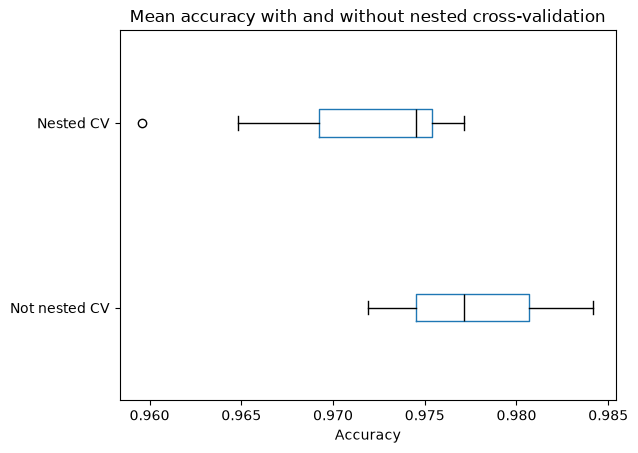

{'Not nested CV': 0.978, 'Nested CV': 0.972}


In [22]:
all_scores = pd.DataFrame({"Not nested CV": not_nested, "Nested CV": nested_scores})
all_scores.plot.box(vert=False, color={"whiskers": "black", "medians": "black", "caps": "black"})
plt.xlabel("Accuracy")
plt.title("Mean accuracy with and without nested cross-validation")
plt.show()
print(all_scores.mean().round(3).to_dict())

The non-nested scores are systematically higher: the search reports the maximum of several noisy scores, and the maximum of noisy numbers is biased upwards. The outer loop scores the whole procedure on data it never used for any choice. When optimising any part of a pipeline (hyperparameters, features, the model itself), evaluate the procedure with nested cross-validation or with a held-out test set.

**In practice.**
- Small-sample biomedical studies (gene expression, neuroimaging) use nested cross-validation to avoid reporting over-optimistic accuracy after model selection (Varma & Simon, 2006; Cawley & Talbot, 2010).
- Benchmarks of automated machine learning systems evaluate each system's whole tuning procedure on outer folds, because each system tunes internally.

> 📖 **Read more:** [extras/18-nested-cross-validation.ipynb](extras/18-nested-cross-validation.ipynb) (INRIA scikit-learn MOOC): the full example with 20 trials.
>
> 📖 **Read more:** [extras/19-nested-cv-sklearn.ipynb](extras/19-nested-cv-sklearn.ipynb) (scikit-learn gallery): nested and non-nested cross-validation of an SVM on the iris data, repeated 30 times, with the difference plotted per trial.

## 6 · The final test on held-out data

**Concept.** The last step of every project is a single evaluation of the final, chosen model on data that played no part in any decision: the **held-out test set**. Everything before it (feature choices, model choice, tuning) used only the development data and cross-validation. The test score, with a bootstrap interval, is the number you report. The held-out data must match the use: for a price suggestion for new hosts, hosts the model has never seen; when the model will predict the future, the *latest* period (an **out-of-time** test).

**Why it matters.** The final test protects against all forms of selection on the development data at once, including choices you did not notice you were making. A clear gap between validation and test scores is itself a finding: it points to leakage, drift or an unsuitable validation scheme.

**Predict before running:** will the test MAE be close to the nested estimate, or clearly worse?

Next we take the search from section 4, which has already refitted the best setting on all development hosts, and predict the locked test hosts once. `np.exp` turns the log predictions into euros.

In [23]:
from sklearn.metrics import mean_absolute_error, r2_score

pred = search.predict(X_test)                                  # the one and only look at the test hosts
abs_err = np.abs(np.exp(y_test.to_numpy()) - np.exp(pred))
print("chosen setting:", search.best_params_)
print(f"test R2 {r2_score(y_test, pred):.3f};  log-scale MAE {mean_absolute_error(y_test, pred):.4f};  MAE EUR {abs_err.mean():.1f}")

chosen setting: {'model': Lasso(max_iter=5000), 'model__alpha': 0.0003}
test R2 0.568;  log-scale MAE 0.2640;  MAE EUR 49.0


The log-scale MAE on the test hosts (0.2640) can be compared directly with the nested estimate (0.2686). They agree within 0.005, about half a percentage point of typical error: the validation scheme of this block, host-grouped folds with tuning inside, predicted what happened on new hosts.

**In practice.**
- Regulated industries require independent validation on held-out data before a model is approved; in banking, model risk guidance such as the US Federal Reserve's SR 11-7 (2011) asks for outcome analysis and back-testing by a function independent of the developers.
- Clinical prediction models are expected to undergo external validation on patients from other hospitals or later years (TRIPOD guideline), which often reveals a drop in performance.

> **Note.** If you evaluate on the test set, change something and evaluate again, the test set has become a validation set. If that happens, say so in your report and, if possible, hold back a fresh test set.

## 7 · Worked example · What error should a first-time host expect from the tuned model?

The test MAE is one number from 1,254 listings of 748 hosts. To report it honestly we add a 95 % **cluster-bootstrap** interval that resamples hosts (block 1, section 5). Next we sum errors and count listings per host, then draw hosts with replacement.

In [24]:
by_host = pd.Series(abs_err).groupby(hosts_all.iloc[test].to_numpy())
sums, counts = by_host.sum().to_numpy(), by_host.size().to_numpy()
rng = np.random.default_rng(0)
boot = []
for _ in range(1000):
    pick = rng.integers(0, len(sums), len(sums))
    boot.append(sums[pick].sum() / counts[pick].sum())
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"MAE EUR {abs_err.mean():.1f}, 95 % cluster-bootstrap interval {lo:.1f} to {hi:.1f};"
      f" median price of the test listings EUR {np.median(np.exp(y_test)):.0f}")

MAE EUR 49.0, 95 % cluster-bootstrap interval 43.7 to 54.5; median price of the test listings EUR 160


| Step | Data used | Number |
|---|---|---|
| `best_score_` of the ridge-or-lasso search | development hosts, folds used for the choice | log-scale MAE 0.2684 |
| Nested cross-validation | development hosts, outer folds never used for a choice | log-scale MAE 0.2686 |
| Final test | 748 locked hosts, used once | log-scale MAE 0.2640; **€49.0** (95 % interval €43.7 to €54.5) |

**Answer to the practice question.** A host who lists a first flat in Berlin can expect the tuned linear price model to be off by about 49.0 euros a night on average (95 % interval 43.7 to 54.5 euros), about a third of the median price of 160 euros. Block 1's untuned gradient boosting reached €50.8 on the same test hosts; the two intervals overlap, so tuning a linear model with 480 columns did not demonstrably beat it. The leaking workflow of block 1 had promised €27; nothing like that is reached on new hosts. The honest report says so.

> **Note.** In the course leaderboard (Sessions 13–16) the hidden test labels play the same role as our locked hosts: you submit predictions, you never see the labels.

## Check your understanding

1. Name two parameters and two hyperparameters of the ridge price pipeline (imputer, scaler, one-hot encoder, ridge).
2. With 1,000 listings, the unpenalised price model has a high training R² and a validation R² near zero. What is the diagnosis, and why is it much milder with all listings?
3. A learning curve shows training and validation R² both at 0.62 and flat. Will collecting more listings help? What would you try instead?
4. In nested cross-validation, which loop chooses the hyperparameters and which loop produces the number you report?
5. Your random cross-validation of a price model gives an MAE of €28, the held-out hosts give €52. List three possible explanations.

## Exercises (30 min)

Work in pairs. The lecturer chooses which exercises to set; there are more than fit into 30 minutes. *Paper* and *Predict* tasks are answered in the markdown cell below the task, before any code is run.

### 2.1 · Ridge as λ → ∞

*Predict · 5 min*

> What happens to the coefficients of a ridge regression when the penalty λ (scikit-learn: `alpha`) grows without limit? Sketch why the lasso sets coefficients exactly to zero and ridge does not.

*Source:* [*The Elements of Statistical Learning*, §3.4, Figure 3.11](https://hastie.su.domains/ElemStatLearn/)

*Your answer:*

### 2.2 · Sketch the learning curves

*Paper · 10 min*

> Sketch training and validation error against training size for an underfitting and an overfitting model. Then compare with the real curves.

*Source:* original exercise for this course; background: [scikit-learn: Validation and learning curves](https://scikit-learn.org/stable/modules/learning_curve.html)

*Your answer:*

### 2.3 · The public leaderboard trap

*Code · 15 min*

> A test set of 200 random labels, split into a public and a private half. Generate 100 random submissions and choose the best on the public half. How good is it on the private half?

*Source:* [Blum & Hardt (2015), "The Ladder: a reliable leaderboard for machine learning competitions"](https://arxiv.org/abs/1502.04585)

### 2.4 · The test set used fifty times

*Class · 5 min*

> A team evaluates on its test set after every change, fifty times in total. Is it still a test set?

*Source:* [Dwork et al. (2015), "The reusable holdout", *Science*](https://doi.org/10.1126/science.aaa9375) ([arXiv](https://arxiv.org/abs/1506.02629))

*Your answer:*

### 2.5 · How many neighbours for a price?

*Code · 25 min* · *Stretch:*

> Use the development data of this notebook with the small numeric feature table of the starter cell (`X_knn`, `y`, `hosts`). Put a `SimpleImputer(strategy="median")`, a `StandardScaler` and a `KNeighborsRegressor` in a pipeline and tune `n_neighbors` (for example 5, 10, 20, 50, 100) with `GridSearchCV` and host-grouped folds (`GroupKFold(5)`, pass `groups=hosts` to `fit`). Report `best_params_` and `best_score_` (R² on the log price).
>
> Then estimate the tuned procedure without optimism with nested cross-validation (inner `GroupKFold(3)`, outer `GroupKFold(5)`). Is the nested estimate lower than `best_score_`? Is k-NN better or worse than the ridge model of this notebook?

*Source:* original exercise for this course; background: [scikit-learn: Tuning the hyper-parameters of an estimator](https://scikit-learn.org/stable/modules/grid_search.html)

In [25]:
# Starter: size, location, reviews, room type and district of the development listings
X_knn = pd.get_dummies(bnb.iloc[dev][["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "room_type",
                                      "district", "number_of_reviews", "review_scores_rating", "availability_365"]],
                       columns=["room_type", "district"], dtype=int)
print(X_knn.shape)

(5421, 24)


## Debrief (15 min)

- **Compare** two sketches from 2.2. Look for the typical mistake: a validation error drawn *below* the training error for a large training set. Ask why that cannot happen on average.
- **In 2.3**, ask why the best public score is far above 50 % while the private score is not. Connect it to `best_score_` and to section 5: choosing the maximum of many noisy scores inflates it.
- **In 2.5**, compare the nested estimate with `best_score_`, and check that the pair passed `groups=hosts` to the outer and the inner loop.
- **Bridge to the team project and Session 8.** Write your validation plan now: which split (by time, by group), which metric, how you will report its uncertainty, and which inputs may not be used. Session 8 moves to classification, where the metric itself (precision, recall, ROC AUC) becomes a choice, and the `Pipeline` grows a `ColumnTransformer`.

## Further reading

**Textbooks and guides this block follows**

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Chapter 6 "Linear Model Selection and Regularization". Springer. https://www.statlearning.com/
- scikit-learn developers. *Tuning the hyper-parameters of an estimator* and *Validation curves: plotting scores to evaluate models*. https://scikit-learn.org/stable/modules/grid_search.html · https://scikit-learn.org/stable/modules/learning_curve.html
- INRIA. *scikit-learn MOOC*, Module 2 "Selecting the best model", Module 3 "Hyperparameter tuning" and Module 4 "Linear models". https://inria.github.io/scikit-learn-mooc/

**Papers and reports cited**

- Banko, M. & Brill, E. (2001). Scaling to very very large corpora for natural language disambiguation. *Proceedings of ACL 2001*, 26–33. https://aclanthology.org/P01-1005/
- Bergstra, J. & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281–305. https://jmlr.org/papers/v13/bergstra12a.html
- Board of Governors of the Federal Reserve System (2011). *SR 11-7: Guidance on Model Risk Management*. https://www.federalreserve.gov/supervisionreg/srletters/sr1107.htm
- Cawley, G. C. & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *JMLR*, 11, 2079–2107. https://jmlr.org/papers/v11/cawley10a.html
- Feurer, M. et al. (2015). Efficient and robust automated machine learning. *NeurIPS 28*. https://papers.nips.cc/paper/5872-efficient-and-robust-automated-machine-learning
- Hoerl, A. E. & Kennard, R. W. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67. https://doi.org/10.1080/00401706.1970.10488634
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society B*, 58(1), 267–288. https://doi.org/10.1111/j.2517-6161.1996.tb02080.x
- Varma, S. & Simon, R. (2006). Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, 7, 91. https://doi.org/10.1186/1471-2105-7-91

**Curated sources (reused with attribution)**

- INRIA scikit-learn MOOC notebooks "Regularization of linear regression model", "Overfit-generalization-underfit", "Effect of the sample size in cross-validation", "Hyperparameter tuning by grid-search", "Hyperparameter tuning by randomized-search" and "Nested cross-validation" (CC BY 4.0): sections 2–5; figures `cross_validation_train_test_diagram.png` and `grid_vs_random_search.svg`.
- ISLP Lab 6 "Linear Models and Regularization Methods" (BSD-2-Clause): section 2.
- scikit-learn gallery, "Custom refit strategy of a grid search with cross-validation" (BSD-3-Clause): section 4.

**Data.** Inside Airbnb (2026), *Berlin, Germany*, snapshot of 26 June 2026, CC BY 4.0, https://insideairbnb.com/get-the-data/ · Breast cancer Wisconsin (diagnostic) data shipped with scikit-learn.

**Extras for this block:** [01](extras/01-model-validation.ipynb) model validation (PDSH) · [10](extras/10-ridge-regularisation.ipynb) ridge regularisation · [11](extras/11-islp-ridge-lasso-lab.ipynb) ISLP ridge and lasso lab · [12](extras/12-validation-curve.ipynb) validation curve · [13](extras/13-learning-curve.ipynb) learning curve · [14](extras/14-learning-curve-sklearn.ipynb) learning curves (gallery) · [15](extras/15-grid-search.ipynb) grid search · [16](extras/16-randomized-search.ipynb) randomised search · [17](extras/17-grid-search-custom-refit.ipynb) custom refit · [18](extras/18-nested-cross-validation.ipynb) nested CV · [19](extras/19-nested-cv-sklearn.ipynb) nested CV (gallery) · [20](extras/20-case-study-churn-validation.ipynb) churn model validation. Provenance: [extras/README.md](extras/README.md).